# Prune, quantize, or both? 1. Rebuilding DeiT-Small

Before compressing DeiT-Small we rebuild it from scratch, so that every layer we later prune or quantize is code we can read. The notebook re-implements DeiT-S (ViT-S/16) in plain PyTorch without `timm` modules, loads the official weights (`deit_small_patch16_224.fb_in1k`) and checks that it computes the same function as the `timm` reference. It then reproduces the published top-1 on ImageNet-V2 matched-frequency, for DeiT-S and for DeiT-Ti, the smaller model we compare against, and accounts for where the bytes are, since the real file size is the x-axis of every curve in the project. Nothing is compressed yet; that starts in notebook 02.

The data is ImageNet-V2 matched-frequency (10 000 images, Recht et al., 2019). Set `IMAGENETV2_DIR` if it is not at the default path. Reference numbers for ImageNet-1k val are quoted from the DeiT paper and timm.

In [1]:
import os, json, time, platform, tempfile
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import timm
from timm.data import resolve_data_config, create_transform
from PIL import Image
import matplotlib.pyplot as plt
from safetensors.torch import save_file

# Exact FP32 arithmetic for the equivalence checks (no TF32 on Ampere/Ada).
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.manual_seed(0)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
V2_DIR = Path(os.environ.get("IMAGENETV2_DIR", "../data/imagenetv2-matched-frequency-format-val"))
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RESULTS = {}

print("python", platform.python_version(), "| torch", torch.__version__, "| timm", timm.__version__)
print("device:", torch.cuda.get_device_name() if DEVICE == "cuda" else "cpu")
print("ImageNet-V2 found:", V2_DIR.exists())

python 3.10.22 | torch 2.11.0+cu128 | timm 1.0.30
device: NVIDIA GeForce RTX 4070
ImageNet-V2 found: True


## 1. DeiT-S from scratch

DeiT keeps the ViT architecture unchanged (Dosovitskiy et al., 2021; Touvron et al., 2021); only the training recipe differs. DeiT-S: patch 16 × 16, embedding dimension 384, 6 heads of 64 dimensions, 12 pre-norm blocks, MLP ratio 4 (384 → 1536 → 384), a class token, learned position embeddings, and a linear head on the class token.

Per block, with $x \in \mathbb{R}^{197 \times 384}$ (196 patches + class token):

$$x \leftarrow x + \mathrm{proj}\big(\mathrm{MHA}(\mathrm{LN}_1(x))\big), \qquad x \leftarrow x + \mathrm{fc_2}\big(\mathrm{GELU}(\mathrm{fc_1}(\mathrm{LN}_2(x)))\big)$$

$$\mathrm{head}_k = \mathrm{softmax}\!\left(\frac{Q_k K_k^\top}{\sqrt{64}}\right) V_k, \qquad k = 1, \dots, 6$$

The module names match timm's (`blocks.{l}.attn.qkv`, `blocks.{l}.mlp.fc1`, …) so the pretrained `state_dict` loads with `strict=True`. Attention is written out explicitly, without a fused kernel, so that whole heads can be removed later.

In [2]:
class PatchEmbed(nn.Module):
    # A 16x16 conv with stride 16 is the same as flattening each patch and applying one linear layer.
    def __init__(self, img_size=224, patch_size=16, in_chans=3, dim=384):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_chans, dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):                      # (B, 3, 224, 224)
        x = self.proj(x)                       # (B, 384, 14, 14)
        return x.flatten(2).transpose(1, 2)    # (B, 196, 384)


class Attention(nn.Module):
    def __init__(self, dim=384, num_heads=6):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(dim, 3 * num_heads * self.head_dim)   # rows: [q heads | k heads | v heads]
        self.proj = nn.Linear(num_heads * self.head_dim, dim)
        self.last_attn = None                  # filled when record_attn=True

    def forward(self, x, record_attn=False):
        B, N, _ = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)                # each (B, H, N, 64)
        attn = (q * self.scale) @ k.transpose(-2, -1)
        attn = attn.softmax(dim=-1)            # (B, H, N, N)
        if record_attn:
            self.last_attn = attn.detach()
        x = (attn @ v).transpose(1, 2).reshape(B, N, self.num_heads * self.head_dim)
        return self.proj(x)


class Mlp(nn.Module):
    def __init__(self, dim=384, hidden=1536):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()                   # exact (erf) GELU, as in the checkpoint
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class Block(nn.Module):
    def __init__(self, dim=384, num_heads=6, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, num_heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, int(dim * mlp_ratio))

    def forward(self, x, record_attn=False):
        x = x + self.attn(self.norm1(x), record_attn)
        x = x + self.mlp(self.norm2(x))
        return x


class DeiT(nn.Module):
    def __init__(self, dim=384, depth=12, num_heads=6, num_classes=1000):
        super().__init__()
        self.patch_embed = PatchEmbed(dim=dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.num_patches + 1, dim))
        self.blocks = nn.ModuleList([Block(dim, num_heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, return_hidden=False, record_attn=False):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        hidden = []
        for blk in self.blocks:
            x = blk(x, record_attn)
            hidden.append(x)
        logits = self.head(self.norm(x)[:, 0])  # classify from the class token
        return (logits, hidden) if return_hidden else logits


def deit_small(): return DeiT(dim=384, depth=12, num_heads=6)
def deit_tiny():  return DeiT(dim=192, depth=12, num_heads=3)

## 2. Load the pretrained weights

The weights come from timm (`deit_small_patch16_224.fb_in1k`, the official Meta checkpoint, Apache-2.0). We copy the `state_dict` into our model with `strict=True`: every tensor must have a matching name and shape, with nothing missing and nothing extra.

In [3]:
ref_s = timm.create_model("deit_small_patch16_224.fb_in1k", pretrained=True).eval()
ref_t = timm.create_model("deit_tiny_patch16_224.fb_in1k", pretrained=True).eval()

ours_s, ours_t = deit_small().eval(), deit_tiny().eval()
print("DeiT-S:", ours_s.load_state_dict(ref_s.state_dict(), strict=True))
print("DeiT-Ti:", ours_t.load_state_dict(ref_t.state_dict(), strict=True))

n_params = lambda m: sum(p.numel() for p in m.parameters())
for name, a, b in [("DeiT-S", ours_s, ref_s), ("DeiT-Ti", ours_t, ref_t)]:
    print(f"{name}: ours {n_params(a):,} params | timm {n_params(b):,} params")
assert n_params(ours_s) == n_params(ref_s) == 22_050_664
RESULTS["params"] = {"deit_s": n_params(ours_s), "deit_ti": n_params(ours_t)}

DeiT-S: <All keys matched successfully>
DeiT-Ti: <All keys matched successfully>
DeiT-S: ours 22,050,664 params | timm 22,050,664 params
DeiT-Ti: ours 5,717,416 params | timm 5,717,416 params


## 3. Does it compute the same function?

Same weights do not guarantee the same function: a wrong head split, a wrong LayerNorm epsilon or the tanh-approximated GELU would all load cleanly and still change the outputs. We compare logits and the output of every block against timm on random inputs and on real images, in FP32 without TF32. timm uses PyTorch's fused `scaled_dot_product_attention` and we use an explicit softmax, so we expect differences at the level of floating-point rounding (≈ 1e-5), not zero.

In [4]:
cfg = resolve_data_config({}, model=ref_s)
tfm = create_transform(**cfg)            # resize 248 (bicubic) -> center crop 224 -> ImageNet mean/std
print(cfg)

@torch.no_grad()
def compare(ours, ref, x):
    ours, ref, x = ours.to(DEVICE), ref.to(DEVICE), x.to(DEVICE)
    lo, hidden = ours(x, return_hidden=True)
    feats, h = [], ref.patch_embed(x)
    h = ref._pos_embed(h)
    for blk in ref.blocks:
        h = blk(h); feats.append(h)
    lr = ref(x)
    return {
        "max_abs_logit_diff": (lo - lr).abs().max().item(),
        "max_rel_logit_diff": ((lo - lr).abs().max() / lr.abs().max()).item(),
        "max_abs_block_diff": max((a - b).abs().max().item() for a, b in zip(hidden, feats)),
        "argmax_agreement": (lo.argmax(1) == lr.argmax(1)).float().mean().item(),
    }

x_rand = torch.randn(32, 3, 224, 224)
v2_files = sorted(V2_DIR.glob("*/*.jpeg"))
x_real = torch.stack([tfm(Image.open(f).convert("RGB")) for f in v2_files[::313][:32]])

for name, x in [("random", x_rand), ("ImageNet-V2 images", x_real)]:
    r = compare(ours_s, ref_s, x)
    print(f"{name:>20}: " + ", ".join(f"{k}={v:.2e}" if k != "argmax_agreement" else f"{k}={v:.3f}" for k, v in r.items()))
RESULTS["equivalence_real_images"] = r
assert r["max_abs_logit_diff"] < 1e-3 and r["argmax_agreement"] == 1.0

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.9, 'crop_mode': 'center'}


              random: max_abs_logit_diff=6.91e-06, max_rel_logit_diff=3.17e-06, max_abs_block_diff=5.04e-04, argmax_agreement=1.000
  ImageNet-V2 images: max_abs_logit_diff=1.67e-05, max_rel_logit_diff=1.72e-06, max_abs_block_diff=1.95e-03, argmax_agreement=1.000


## 4. Accuracy on ImageNet-V2 (matched-frequency)

ImageNet-V2 re-collected new test images for the same 1 000 classes following the original protocol, and models lose 11–14 points on it (Recht et al., 2019). It is one of our two test sets for distribution shift, and here it checks that our rebuild reproduces published numbers. References (timm results tables): DeiT-S 68.53 %, DeiT-Ti 59.92 % top-1. The folder names are class indices `"0"…"999"`, which we map to integers ourselves (`ImageFolder` would sort them as strings).

The 95 % interval is a percentile bootstrap over images (2 000 resamples).

In [5]:
class FolderByIndex(torch.utils.data.Dataset):
    def __init__(self, root, transform):
        self.items = [(f, int(f.parent.name)) for f in sorted(Path(root).glob("*/*.jpeg"))]
        self.transform = transform
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        f, y = self.items[i]
        return self.transform(Image.open(f).convert("RGB")), y

v2 = FolderByIndex(V2_DIR, tfm)
loader = torch.utils.data.DataLoader(v2, batch_size=250, num_workers=8, pin_memory=True)
print(len(v2), "images")

@torch.no_grad()
def predict(models, loader):
    for m in models.values(): m.to(DEVICE).eval()
    logits = {k: [] for k in models}; labels = []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        for k, m in models.items(): logits[k].append(m(x).float().cpu())
        labels.append(y)
    return {k: torch.cat(v) for k, v in logits.items()}, torch.cat(labels)

def bootstrap_ci(correct, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(correct), size=(n_boot, len(correct)))
    accs = correct[idx].mean(1)
    return np.percentile(accs, [2.5, 97.5]) * 100

t0 = time.time()
logits, labels = predict({"ours_s": ours_s, "timm_s": ref_s, "ours_ti": ours_t, "timm_ti": ref_t}, loader)
print(f"evaluated in {time.time() - t0:.0f} s")

published = {"ours_s": 68.53, "timm_s": 68.53, "ours_ti": 59.92, "timm_ti": 59.92}
acc_table = {}
for k, lg in logits.items():
    correct = (lg.argmax(1) == labels).numpy().astype(float)
    top5 = (lg.topk(5, 1).indices == labels[:, None]).any(1).float().mean().item() * 100
    lo, hi = bootstrap_ci(correct)
    acc_table[k] = {"top1": correct.mean() * 100, "ci95": [lo, hi], "top5": top5}
    print(f"{k:>8}: top-1 {correct.mean()*100:.2f} % [{lo:.2f}, {hi:.2f}] | top-5 {top5:.2f} % | published top-1 {published[k]:.2f} %")

agree_s = (logits["ours_s"].argmax(1) == logits["timm_s"].argmax(1)).float().mean().item()
agree_t = (logits["ours_ti"].argmax(1) == logits["timm_ti"].argmax(1)).float().mean().item()
print(f"prediction agreement with timm: DeiT-S {agree_s*100:.2f} %, DeiT-Ti {agree_t*100:.2f} %")
RESULTS["imagenet_v2"] = {"acc": acc_table, "agreement_s": agree_s, "agreement_ti": agree_t, "published_timm": {"deit_s": 68.53, "deit_ti": 59.92}}

10000 images


evaluated in 29 s
  ours_s: top-1 68.52 % [67.63, 69.48] | top-5 88.16 % | published top-1 68.53 %
  timm_s: top-1 68.52 % [67.63, 69.48] | top-5 88.16 % | published top-1 68.53 %


 ours_ti: top-1 59.81 % [58.86, 60.84] | top-5 82.69 % | published top-1 59.92 %
 timm_ti: top-1 59.81 % [58.86, 60.84] | top-5 82.69 % | published top-1 59.92 %
prediction agreement with timm: DeiT-S 100.00 %, DeiT-Ti 100.00 %


Our DeiT-S gives 68.52 % against the published 68.53 %, and its predictions agree with timm on all 10 000 images. DeiT-Ti gives 59.81 % against 59.92 % in timm's table; timm's own model gives the same 59.81 % in our pipeline, so the 0.1-point gap comes from evaluation details (library versions, JPEG decoding), not from the rebuild, and it lies within the confidence interval. With n = 10 000 the interval is about ±0.9 points, so differences between compressed models smaller than that need a paired test.

## 5. Where the bytes are

The x-axis of every curve in this project is the real size of the saved model in bytes. Parameter count and "parameters × bits / 8" are proxies that can disagree with it. First, how the 22.05 M parameters are distributed:

In [6]:
def breakdown(m):
    groups = {"attention (qkv + proj)": 0, "MLP (fc1 + fc2)": 0, "LayerNorms": 0,
              "patch embedding": 0, "cls + position embeddings": 0, "classifier head": 0}
    for n, p in m.named_parameters():
        if ".attn." in n: groups["attention (qkv + proj)"] += p.numel()
        elif ".mlp." in n: groups["MLP (fc1 + fc2)"] += p.numel()
        elif "norm" in n: groups["LayerNorms"] += p.numel()
        elif n.startswith("patch_embed"): groups["patch embedding"] += p.numel()
        elif n in ("cls_token", "pos_embed"): groups["cls + position embeddings"] += p.numel()
        elif n.startswith("head"): groups["classifier head"] += p.numel()
    return groups

bd = breakdown(ours_s); total = sum(bd.values())
for k, v in bd.items(): print(f"{k:>28}: {v:>11,}  ({v/total*100:5.1f} %)")
print(f"{'total':>28}: {total:>11,}")
RESULTS["breakdown_deit_s"] = bd

      attention (qkv + proj):   7,096,320  ( 32.2 %)
             MLP (fc1 + fc2):  14,178,816  ( 64.3 %)
                  LayerNorms:      19,200  (  0.1 %)
             patch embedding:     295,296  (  1.3 %)
   cls + position embeddings:      76,032  (  0.3 %)
             classifier head:     385,000  (  1.7 %)
                       total:  22,050,664


The four linear layers of each block (`qkv`, `proj`, `fc1`, `fc2`) hold about 96 % of the weights, and the MLP alone holds two thirds. These are the layers our method prunes and quantizes, while the rest (patch embedding, embeddings, LayerNorms, biases, head) stays in FP16.

We compare three measures of size. The nominal size is all parameters × bits / 8, which is what papers usually imply. The accounted size adds what a real file must also store, the FP16 scales and zero-points of the quantized block linears (per group of 64 weights, or per output row at INT8) and every other tensor in FP16; here it is a computed figure, and notebook 02 replaces it with the size of the packed file. The file size is the `safetensors` file on disk, measured now for FP32 and FP16.

In [7]:
def file_mb(model, dtype):
    sd = {k: v.detach().to(dtype).contiguous() for k, v in model.state_dict().items()}
    with tempfile.TemporaryDirectory() as d:
        path = Path(d) / "m.safetensors"; save_file(sd, str(path))
        return path.stat().st_size / 1e6

def accounted_mb(model, bits, group=64):
    lin = [m for n, m in model.named_modules() if isinstance(m, nn.Linear) and n.startswith("blocks.")]
    n_lin = sum(m.weight.numel() for m in lin)
    if bits == 8:   meta = sum(m.out_features for m in lin) * 2                 # one FP16 scale per output row
    else:           meta = sum(m.weight.numel() // group for m in lin) * 4      # FP16 scale + FP16 zero per group
    fixed_fp16 = (n_params(model) - n_lin) * 2
    return (n_lin * bits / 8 + meta + fixed_fp16) / 1e6

rows = []
for name, m in [("DeiT-S", ours_s), ("DeiT-Ti", ours_t)]:
    P = n_params(m)
    rows.append((name, "FP32", P * 4 / 1e6, file_mb(m, torch.float32)))
    rows.append((name, "FP16", P * 2 / 1e6, file_mb(m, torch.float16)))
    for b in ([8, 6, 4, 3] if name == "DeiT-S" else [8, 4]):
        rows.append((name, f"INT{b}", P * b / 8 / 1e6, accounted_mb(m, b)))

print(f"{'model':<8} {'format':<6} {'nominal MB':>11} {'real/accounted MB':>18} {'gap':>7}")
for name, fmt, nom, real in rows:
    print(f"{name:<8} {fmt:<6} {nom:>11.2f} {real:>18.2f} {(real/nom-1)*100:>6.1f}%")
RESULTS["sizes_mb"] = [{"model": a, "format": b, "nominal": c, "real_or_accounted": d, "measured_file": b in ("FP32", "FP16")} for a, b, c, d in rows]

model    format  nominal MB  real/accounted MB     gap
DeiT-S   FP32         88.20              88.22    0.0%
DeiT-S   FP16         44.10              44.12    0.0%
DeiT-S   INT8         22.05              22.95    4.1%
DeiT-S   INT6         16.54              18.89   14.2%
DeiT-S   INT4         11.03              13.58   23.2%
DeiT-S   INT3          8.27              10.92   32.1%
DeiT-Ti  FP32         22.87              22.88    0.1%
DeiT-Ti  FP16         11.43              11.45    0.1%
DeiT-Ti  INT8          5.72               6.17    7.9%
DeiT-Ti  INT4          2.86               3.80   33.1%


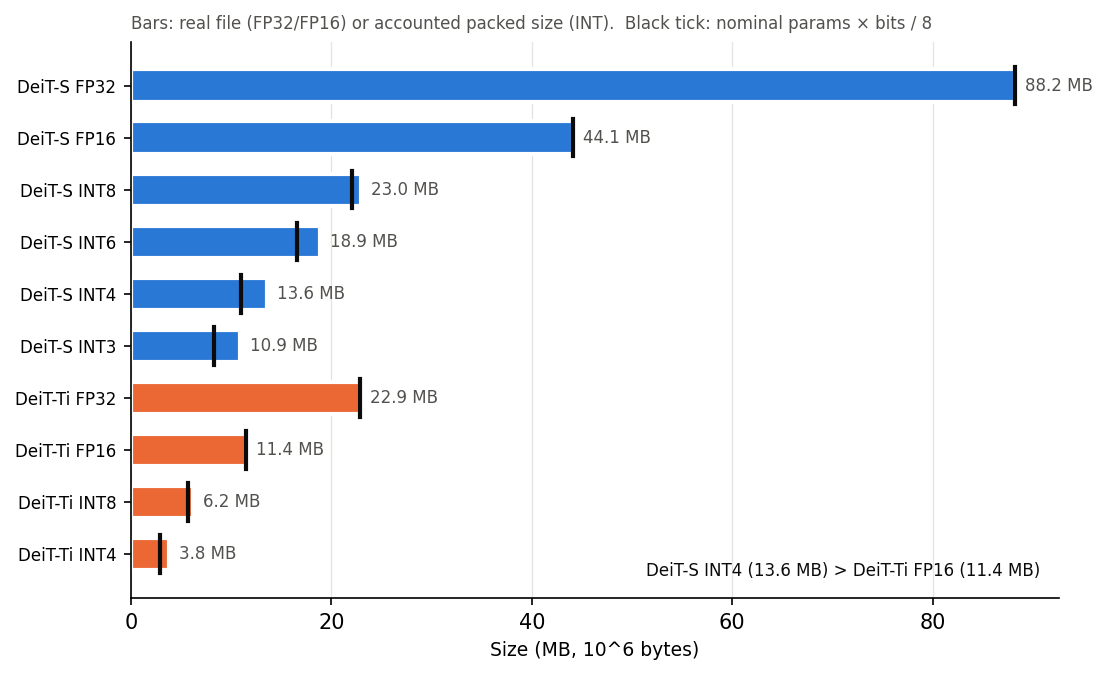

In [8]:
# Figure: nominal vs real/accounted size. One measure (MB) on one axis; colour = model.
C = {"DeiT-S": "#2a78d6", "DeiT-Ti": "#eb6834"}
order = [r for r in rows if r[0] == "DeiT-S"] + [r for r in rows if r[0] == "DeiT-Ti"]
fig, ax = plt.subplots(figsize=(7.5, 4.6), dpi=150)
y = np.arange(len(order))[::-1]
for yi, (name, fmt, nom, real) in zip(y, order):
    ax.barh(yi, real, height=0.62, color=C[name], edgecolor="white", linewidth=2)
    ax.plot([nom, nom], [yi - 0.36, yi + 0.36], color="#0b0b0b", lw=2)
    ax.text(real + 1.0, yi, f"{real:.1f} MB", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, [f"{n} {f}" for n, f, *_ in order], fontsize=8)
ax.set_xlabel("Size (MB, 10^6 bytes)", fontsize=9)
ax.set_title("Bars: real file (FP32/FP16) or accounted packed size (INT).  Black tick: nominal params × bits / 8",
             fontsize=8, loc="left", color="#52514e")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e4e3df", lw=0.6); ax.set_axisbelow(True)
s_int4 = next(r[3] for r in rows if r[:2] == ("DeiT-S", "INT4"))
ti_fp16 = next(r[3] for r in rows if r[:2] == ("DeiT-Ti", "FP16"))
ax.text(0.98, 0.04, f"DeiT-S INT4 ({s_int4:.1f} MB) > DeiT-Ti FP16 ({ti_fp16:.1f} MB)", transform=ax.transAxes,
        ha="right", fontsize=8, color="#0b0b0b")
plt.tight_layout(); plt.savefig(OUT / "fig_sizes.png", dpi=300); plt.savefig(OUT / "fig_sizes.pdf"); plt.show()

The overhead grows as the bit width shrinks. Scales, zero-points and the FP16 layers add 4 % to the nominal size of DeiT-S at INT8, 23 % at INT4 and 32 % at INT3, so a "W4" label understates the size by about a quarter.

The second point shapes the rest of the project. DeiT-S at INT4 is larger than DeiT-Ti at FP16, so at those sizes the useful comparison is between compressed DeiT-S and the smaller dense model, not between compressed and uncompressed DeiT-S. This is why DeiT-Ti appears on every curve.

## 6. Summary

The lines below are regenerated from this run and saved to `outputs/rebuild_summary.json`.

In [9]:
s, t = RESULTS["imagenet_v2"]["acc"]["ours_s"], RESULTS["imagenet_v2"]["acc"]["ours_ti"]
eq = RESULTS["equivalence_real_images"]
print(f"Rebuilt DeiT-S: {RESULTS['params']['deit_s']:,} params, loads the official weights with strict=True")
print(f"Equivalence vs timm (FP32, real images): max |Δlogit| = {eq['max_abs_logit_diff']:.1e}, argmax agreement {eq['argmax_agreement']*100:.0f} %")
print(f"ImageNet-V2 MF top-1: DeiT-S {s['top1']:.2f} % [{s['ci95'][0]:.2f}, {s['ci95'][1]:.2f}] (timm 68.53) | "
      f"DeiT-Ti {t['top1']:.2f} % [{t['ci95'][0]:.2f}, {t['ci95'][1]:.2f}] (timm 59.92)")
print(f"Agreement with timm over 10 000 images: {RESULTS['imagenet_v2']['agreement_s']*100:.2f} %")
with open(OUT / "rebuild_summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)

Rebuilt DeiT-S: 22,050,664 params, loads the official weights with strict=True
Equivalence vs timm (FP32, real images): max |Δlogit| = 1.7e-05, argmax agreement 100 %
ImageNet-V2 MF top-1: DeiT-S 68.52 % [67.63, 69.48] (timm 68.53) | DeiT-Ti 59.81 % [58.86, 60.84] (timm 59.92)
Agreement with timm over 10 000 images: 100.00 %


The next steps place compressed versions of DeiT-S on the accuracy–size chart, first the published post-training methods run under one protocol and then our own per-block mix of pruning and quantization.

### References

- Dosovitskiy, A., et al. (2021). An image is worth 16×16 words: Transformers for image recognition at scale. *ICLR*.
- Recht, B., Roelofs, R., Schmidt, L., & Shankar, V. (2019). Do ImageNet classifiers generalize to ImageNet? *ICML*.
- Touvron, H., Cord, M., Douze, M., Massa, F., Sablayrolles, A., & Jégou, H. (2021). Training data-efficient image transformers & distillation through attention. *ICML*.
- Wightman, R. (2019). PyTorch Image Models (timm). GitHub repository.